In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2
from PIL import Image
from tqdm.auto import tqdm

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

SEED = 42
random.seed(SEED)

np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [5]:
IMG_SIZE = 128
BATCH_SIZE = 1
EPOCHS = 30
MAX_IMAGES = 5000

# Pointing directly to the extracted / attached Edges2Shoes dataset path
SOURCE_DIR = "/kaggle/input/datasets/balraj98/edges2shoes-dataset"
PAIR_DIR = "/kaggle/working/sketch2image_pairs"
MODEL_DIR = "/kaggle/working/pix2pix_checkpoints"

os.makedirs(PAIR_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

if not os.path.isdir(SOURCE_DIR):
    raise FileNotFoundError(
        f"Dataset folder not found: {SOURCE_DIR}. Please check the path."
    )

print("Dataset source folder:", SOURCE_DIR)

Dataset source folder: /kaggle/input/datasets/balraj98/edges2shoes-dataset


Find images and create training pairs

In [6]:
image_paths = []
for root, dirs, files in os.walk(SOURCE_DIR):
    for name in files:
        if name.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(root, name))

random.shuffle(image_paths)
image_paths = image_paths[:MAX_IMAGES]

if not image_paths:
    raise ValueError("No supported image files found in SOURCE_DIR.")

print("Source images selected:", len(image_paths))

from PIL import Image
from tqdm.auto import tqdm
import cv2

saved_paths = []
for i, path in enumerate(tqdm(image_paths)):
    output_path = os.path.join(PAIR_DIR, f"{i:06d}.png")
    try:
        if os.path.exists(output_path):
            saved_paths.append(output_path)
            continue
            
        photo = Image.open(path).convert("RGB")
        photo = photo.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS)
        photo_arr = np.array(photo)
        
        # Convert to grayscale and apply Canny edge detection for shoe outlines
        gray = cv2.cvtColor(photo_arr, cv2.COLOR_RGB2GRAY)
        edges = cv2.Canny(gray, 80, 160)
        sketch = 255 - edges  # White background, black lines
        
        sketch_rgb = np.repeat(sketch[:, :, None], 3, axis=2)
        
        # Concatenate: sketch on left, photo on right
        paired = np.concatenate([sketch_rgb, photo_arr], axis=1)
        Image.fromarray(paired).save(output_path, quality=95)
        saved_paths.append(output_path)
    except Exception as e:
        print("Skipping:", path, "|", e)

print("Total valid pairs created:", len(saved_paths))

Source images selected: 5000


  0%|          | 0/5000 [00:00<?, ?it/s]

Total valid pairs created: 5000


Create the TensorFlow dataset

In [7]:
random.shuffle(saved_paths)
split_index = max(1, min(len(saved_paths) - 1, int(0.9 * len(saved_paths))))
train_files = saved_paths[:split_index]
val_files = saved_paths[split_index:]

def prepare_pair(path):
    image = tf.io.read_file(path)
    image = tf.io.decode_png(image, channels=3)
    
    # Split the paired image into sketch and target photo
    input_image = image[:, :IMG_SIZE, :]
    target_image = image[:, IMG_SIZE:, :]
    
    input_image = tf.cast(input_image, tf.float32)
    target_image = tf.cast(target_image, tf.float32)
    
    # Normalize pixel values from [0, 255] to [-1, 1]
    input_image = input_image / 127.5 - 1.0
    target_image = target_image / 127.5 - 1.0
    
    return input_image, target_image

AUTOTUNE = tf.data.AUTOTUNE

train_data = tf.data.Dataset.from_tensor_slices(train_files)
train_data = train_data.shuffle(min(len(train_files), 1000), seed=SEED)
train_data = train_data.map(prepare_pair, num_parallel_calls=AUTOTUNE)
train_data = train_data.batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_data = tf.data.Dataset.from_tensor_slices(val_files)
val_data = val_data.map(prepare_pair, num_parallel_calls=AUTOTUNE)
val_data = val_data.batch(BATCH_SIZE).prefetch(AUTOTUNE)

print("Training data is ready.")

I0000 00:00:1793087827.316840      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793087827.322911      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Training data is ready.


Visualize training examples

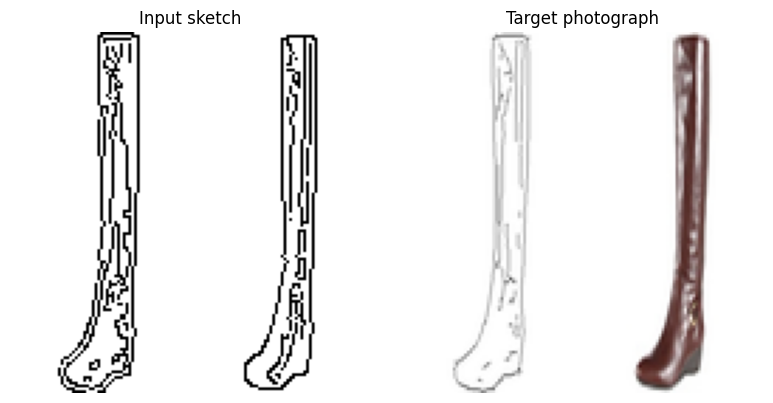

In [8]:
for input_images, target_images in train_data.take(1):
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(np.clip((input_images[0].numpy() + 1) / 2, 0, 1))
    plt.title("Input sketch")
    plt.axis("off")
    
    plt.subplot(1, 2, 2)
    plt.imshow(np.clip((target_images[0].numpy() + 1) / 2, 0, 1))
    plt.title("Target photograph")
    plt.axis("off")
    
    plt.tight_layout()
    plt.show()

In [15]:
from tensorflow.keras.layers import Input, Conv2D, Conv2DTranspose, LeakyReLU, ReLU, Concatenate, BatchNormalization
from tensorflow.keras.models import Model

def downsample(filters, apply_batchnorm=True):
    initializer = tf.random_normal_initializer(0.0, 0.02)
    result = tf.keras.Sequential()
    result.add(Conv2D(filters, kernel_size=4, strides=2, padding="same", kernel_initializer=initializer, use_bias=not apply_batchnorm))
    if apply_batchnorm:
        result.add(BatchNormalization())
    result.add(LeakyReLU(negative_slope=0.2))
    return result

def upsample(filters):
    initializer = tf.random_normal_initializer(0.0, 0.02)
    result = tf.keras.Sequential()
    result.add(Conv2DTranspose(filters, kernel_size=4, strides=2, padding="same", kernel_initializer=initializer, use_bias=False))
    result.add(BatchNormalization())
    result.add(ReLU())
    return result

def build_generator():
    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    
    d1 = downsample(64, apply_batchnorm=False)(inputs)
    d2 = downsample(128)(d1)
    d3 = downsample(256)(d2)
    d4 = downsample(512)(d3)
    d5 = downsample(512)(d4)
    d6 = downsample(512)(d5)
    
    u1 = upsample(512)(d6)
    u1 = Concatenate()([u1, d5])
    
    u2 = upsample(512)(u1)
    u2 = Concatenate()([u2, d4])
    
    u3 = upsample(256)(u2)
    u3 = Concatenate()([u3, d3])
    
    u4 = upsample(128)(u3)
    u4 = Concatenate()([u4, d2])
    
    u5 = upsample(64)(u4)
    u5 = Concatenate()([u5, d1])
    
    initializer = tf.random_normal_initializer(0.0, 0.02)
    outputs = Conv2DTranspose(3, kernel_size=4, strides=2, padding="same", kernel_initializer=initializer, activation="tanh")(u5)
    
    return Model(inputs=inputs, outputs=outputs, name="Generator")

generator = build_generator()
generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_15      │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_14       │ (None, 64, 64,    │      3,136 │ input_layer_15[0… │
│ (Sequential)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_15       │ (None, 32, 32,    │    131,584 │ sequential_14[0]… │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_16       │ (None, 16, 16,    │    525,312 │ sequential_15[0]… │
│ (Sequential)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_17       │ (None, 8, 8, 512) │  2,099,200 │ sequential_16[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_18       │ (None, 4, 4, 512) │  4,196,352 │ sequential_17[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_19       │ (None, 2, 2, 512) │  4,196,352 │ sequential_18[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_20       │ (None, 4, 4, 512) │  4,196,352 │ sequential_19[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 4, 4,      │          0 │ sequential_20[0]… │
│ (Concatenate)       │ 1024)             │            │ sequential_18[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_21       │ (None, 8, 8, 512) │  8,390,656 │ concatenate_6[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 8, 8,      │          0 │ sequential_21[0]… │
│ (Concatenate)       │ 1024)             │            │ sequential_17[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_22       │ (None, 16, 16,    │  4,195,328 │ concatenate_7[0]… │
│ (Sequential)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 16, 16,    │          0 │ sequential_22[0]… │
│ (Concatenate)       │ 512)              │            │ sequential_16[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_23       │ (None, 32, 32,    │  1,049,088 │ concatenate_8[0]… │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_9       │ (None, 32, 32,    │          0 │ sequential_23[0]… │
│ (Concatenate)       │ 256)              │            │ sequential_15[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_24       │ (None, 64, 64,    │    262,400 │ concatenate_9[0]… │
│ (Sequential)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_10      │ (None, 64, 64,    │          0 │ sequential_24[0]

 Total params: 29,251,907 (111.59 MB)

 Trainable params: 29,245,123 (111.56 MB)

 Non-trainable params: 6,784 (26.50 KB)

In [16]:
def build_discriminator():
    initializer = tf.random_normal_initializer(0.0, 0.02)
    
    input_sketch = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_sketch")
    target_photo = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="target_photo")
    
    x = Concatenate()([input_sketch, target_photo])
    
    x = downsample(64, apply_batchnorm=False)(x)
    x = downsample(128)(x)
    x = downsample(256)(x)
    
    x = Conv2D(512, kernel_size=4, strides=1, padding="same", kernel_initializer=initializer)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(negative_slope=0.2)(x)
    
    outputs = Conv2D(1, kernel_size=4, strides=1, padding="same", kernel_initializer=initializer)(x)
    
    return Model(inputs=[input_sketch, target_photo], outputs=outputs, name="Discriminator")

discriminator = build_discriminator()
discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_sketch        │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ target_photo        │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_11      │ (None, 128, 128,  │          0 │ input_sketch[0][… │
│ (Concatenate)       │ 6)                │            │ target_photo[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_25       │ (None, 64, 64,    │      6,208 │ concatenate_11[0… │
│ (Sequential)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_26       │ (None, 32, 32,    │    131,584 │ sequential_25[0]… │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_27       │ (None, 16, 16,    │    525,312 │ sequential_26[0]… │
│ (Sequential)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 16, 16,    │  2,097,664 │ sequential_27[0]… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      2,048 │ conv2d_20[0][0]   │
│ (BatchNormalizatio… │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_19      │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 16, 16, 1) │      8,193 │ leaky_re_lu_19[0… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,771,009 (10.57 MB)

 Trainable params: 2,769,217 (10.56 MB)

 Non-trainable params: 1,792 (7.00 KB)

In [17]:
loss_object = tf.keras.losses.BinaryCrossentropy(from_logits=True)
LAMBDA_L1 = 100

def discriminator_loss(real_output, fake_output):
    real_loss = loss_object(tf.ones_like(real_output), real_output)
    fake_loss = loss_object(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(disc_generated_output, generated_image, target_image):
    adversarial_loss = loss_object(tf.ones_like(disc_generated_output), disc_generated_output)
    l1_loss = tf.reduce_mean(tf.abs(target_image - generated_image))
    total_generator_loss = adversarial_loss + (LAMBDA_L1 * l1_loss)
    return total_generator_loss, adversarial_loss, l1_loss

generator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

In [18]:
# Disable TensorFlow graph layout optimizer to prevent dropout layout mismatch
import tensorflow as tf
tf.config.optimizer.set_experimental_options({'layout_optimizer': False})
print("Layout optimizer disabled.")

Layout optimizer disabled.


In [20]:
@tf.function
def train_step(input_image, target_image):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_image = generator(input_image, training=True)
        
        real_output = discriminator([input_image, target_image], training=True)
        fake_output = discriminator([input_image, generated_image], training=True)
        
        gen_total_loss, gen_adv_loss, gen_l1_loss = generator_loss(fake_output, generated_image, target_image)
        disc_loss = discriminator_loss(real_output, fake_output)
        
    generator_gradients = gen_tape.gradient(gen_total_loss, generator.trainable_variables)
    discriminator_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    
    generator_optimizer.apply_gradients(zip(generator_gradients, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(discriminator_gradients, discriminator.trainable_variables))
    
    return gen_total_loss, disc_loss

print("Starting training loop...")
for epoch in range(EPOCHS):
    disc_losses = []
    gen_losses = []
    
    for input_images, target_images in train_data:
        g_loss, d_loss = train_step(input_images, target_images)
        gen_losses.append(float(g_loss))
        disc_losses.append(float(d_loss))
        
    print(f"Epoch {epoch + 1}/{EPOCHS} | Discriminator Loss: {np.mean(disc_losses):.4f} | Generator Loss: {np.mean(gen_losses):.4f}")

Starting training loop...
Epoch 1/30 | Discriminator Loss: 1.0299 | Generator Loss: 8.1025
Epoch 2/30 | Discriminator Loss: 1.0215 | Generator Loss: 7.9209
Epoch 3/30 | Discriminator Loss: 1.0256 | Generator Loss: 7.7055
Epoch 4/30 | Discriminator Loss: 1.0172 | Generator Loss: 7.4898
Epoch 5/30 | Discriminator Loss: 1.0227 | Generator Loss: 7.2993
Epoch 6/30 | Discriminator Loss: 1.0137 | Generator Loss: 7.1471
Epoch 7/30 | Discriminator Loss: 1.0168 | Generator Loss: 6.9730
Epoch 8/30 | Discriminator Loss: 1.0142 | Generator Loss: 6.8182
Epoch 9/30 | Discriminator Loss: 1.0019 | Generator Loss: 6.7147
Epoch 10/30 | Discriminator Loss: 1.0018 | Generator Loss: 6.6142
Epoch 11/30 | Discriminator Loss: 0.9988 | Generator Loss: 6.5089
Epoch 12/30 | Discriminator Loss: 0.9967 | Generator Loss: 6.4108
Epoch 13/30 | Discriminator Loss: 1.0036 | Generator Loss: 6.3284
Epoch 14/30 | Discriminator Loss: 0.9990 | Generator Loss: 6.2665
Epoch 15/30 | Discriminator Loss: 0.9853 | Generator Loss: 

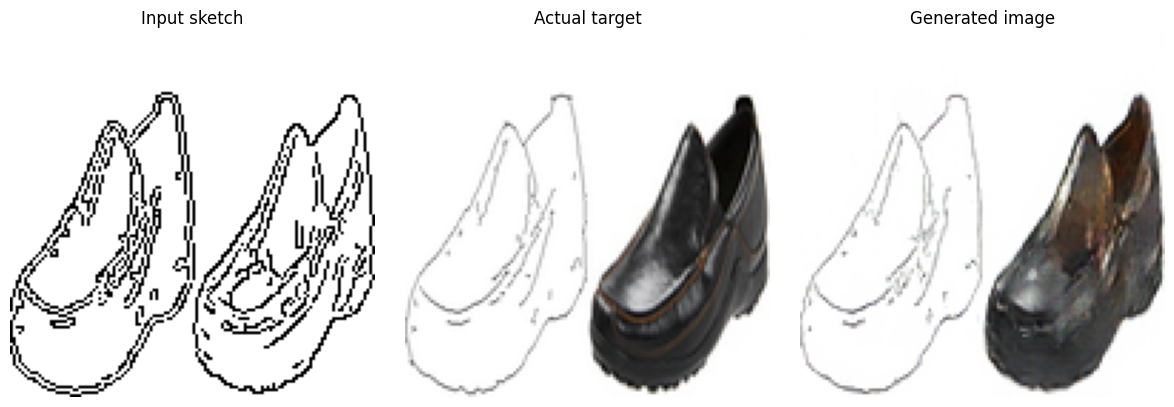

In [21]:
for input_images, target_images in val_data.take(1):
    generated_images = generator(input_images, training=False)
    
    plt.figure(figsize=(12, 4))
    images = [input_images[0], target_images[0], generated_images[0]]
    titles = ["Input sketch", "Actual target", "Generated image"]
    
    for i, (image, title) in enumerate(zip(images, titles)):
        plt.subplot(1, 3, i + 1)
        plt.imshow(np.clip((image.numpy() + 1) / 2, 0, 1))
        plt.title(title)
        plt.axis("off")
        
    plt.tight_layout()
    plt.show()

In [22]:
model_path = "/kaggle/working/pix2pix_generator.keras"
generator.save(model_path)
print("Generator saved:", model_path)
print("File size (MB):", round(os.path.getsize(model_path) / 1e6, 2))

Generator saved: /kaggle/working/pix2pix_generator.keras
File size (MB): 117.18


In [28]:

import io
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import ipywidgets as widgets

from IPython.display import display
from PIL import Image

# Verify that the model is available
assert "generator" in globals(), "Load your trained generator first."
assert "IMG_SIZE" in globals(), "Define IMG_SIZE first."

# Upload widget
uploader = widgets.FileUpload(
    accept=".png,.jpg,.jpeg",
    multiple=False,
    description="Upload Sketch"
)

generate_button = widgets.Button(
    description="Generate Shoe",
    button_style="success"
)

output_area = widgets.Output()

def generate_sketch(_):
    with output_area:
        output_area.clear_output(wait=True)

        try:
            # Get uploaded file
            if not uploader.value:
                print("Please upload a sketch first.")
                return

            uploaded = uploader.value

            # Handle common ipywidgets 7/8 upload formats
            if isinstance(uploaded, dict):
                file_info = next(iter(uploaded.values()))
            else:
                file_info = uploaded[0]

            image_bytes = file_info["content"]

            # Convert sketch to RGB
            image = Image.open(
                io.BytesIO(bytes(image_bytes))
            ).convert("RGB")

            image = image.resize(
                (IMG_SIZE, IMG_SIZE),
                Image.Resampling.LANCZOS
            )

            # Normalize to [-1, 1]
            input_arr = (
                np.asarray(image, dtype=np.float32) / 127.5
            ) - 1.0

            input_batch = np.expand_dims(input_arr, axis=0)

            # Generate image
            generated_batch = generator(
                tf.convert_to_tensor(input_batch),
                training=False
            )

            generated_img = generated_batch[0].numpy()
            generated_img = np.clip(
                (generated_img + 1.0) / 2.0,
                0.0,
                1.0
            )

            # Display input and output
            fig, axes = plt.subplots(1, 2, figsize=(8, 4))

            axes[0].imshow(image)
            axes[0].set_title("Input Sketch")
            axes[0].axis("off")

            axes[1].imshow(generated_img)
            axes[1].set_title("Generated Shoe")
            axes[1].axis("off")

            plt.tight_layout()
            plt.show()

        except Exception as e:
            print(f"Generation failed: {e}")

generate_button.on_click(generate_sketch)

display(
    widgets.VBox([
        widgets.HTML("<h3>Sketch to Image</h3>"),
        uploader,
        generate_button,
        output_area
    ])
)
